# Бензодиазепины в базе нежелательных реакций FAERS

**Зависимость, злоупотребление, синдром отмены, передозировка и сопутствующие опиоиды по данным openFDA**

**Цель.** Описать, как в добровольных отчётах FAERS проявляются зависимость, злоупотребление, синдром отмены и передозировка при четырёх бензодиазепинах (алпразолам, диазепам, лоразепам, клоназепам), какие препараты указываются вместе с ними и связано ли присутствие опиоидов в отчёте с передозировкой.

**Данные.** openFDA, эндпоинт `drug/event`, отчёты за 2019-2025 годы. Для анализа когорты загружена подвыборка (до 2000 отчётов на препарат и год, это 13-34% от доступных). Сигналы безопасности рассчитаны по всей базе.

**Методы.** Когорта по роли «подозреваемый препарат»; группы реакций по терминам MedDRA; доли с доверительными интервалами Уилсона; логистическая регрессия с поправками; PRR и ROR относительно всей базы.

## Ключевые результаты

1. **Диазепам и алпразолам заметно выше клоназепама и лоразепама по злоупотреблению:** 17% и 23% отчётов когорты против 11% и 9%. По всей базе ROR около 22 и 19 против 7.
2. **Диазепам лидирует по передозировке и токсичности:** 30% отчётов широкой группы против 17-22% у остальных, ROR к всей базе 8,4 (алпразолам 5,6, лоразепам и клоназепам около 3). После поправок шансы выше, чем у алпразолама, в 1,7 раза.
3. **Присутствие опиоида в отчёте связано с примерно на 40% более высокими шансами передозировки или токсичности:** ОШ 1,42 (95% ДИ 1,32-1,53) после поправок на возраст, пол, год, препарат, число и классы сопутствующих; 1,39 (1,22-1,58) без отчётов с флагом дубля.
4. **Опиоиды не единственный и не самый сильный из сопутствующих классов:** при антидепрессантах ОШ 1,97, при z-препаратах 1,65, при опиоидах и габапентиноидах по 1,42.
5. **Синдром отмены у разных препаратов почти не различается:** 2-3% отчётов когорты.
6. **Все результаты описывают ассоциации в добровольных отчётах.** Это не причинные эффекты и не частоты побочек в популяции (раздел «Ограничения» в конце).

**Как запускать.** Kernel → Restart & Run All. При первом запуске ноутбук попросит ключ openFDA (бесплатно: https://open.fda.gov/apis/authentication/); он нигде не сохраняется. Если папка `data/` уже заполнена, скачивание пропускается. Раздел 10 делает около 90 лёгких запросов и тоже кэширует результат.

*Пояснения под результатами написаны по запуску на данных, загруженных 15.10.2026. При перекачке данных цифры могут слегка отличаться.*

## 0. Настройки

Список препаратов, годы и размер подвыборки задаются в первой ячейке. Цвет на графиках закреплён за препаратом и не меняется между рисунками.

In [1]:
import json, math, os, re, time, getpass
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ключ берётся из переменной окружения OPENFDA_API_KEY или вводится вручную (в файл не сохраняется)
API_KEY = os.environ.get("OPENFDA_API_KEY") or getpass.getpass("openFDA API key (Enter, если не нужен): ") or None

BASE = "https://api.fda.gov/drug/event.json"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; benzo-faers-portfolio/0.3)", "Accept": "application/json"}
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

BENZOS = ["alprazolam", "diazepam", "lorazepam", "clonazepam"]
YEARS = range(2019, 2026)       # полные годы
MAX_PER_DRUG_YEAR = 2000        # подвыборка на пару «препарат-год» (API отдаёт максимум 25000 по skip)
PAGE_SIZE = 100                 # маленькие порции надёжнее на нестабильной сети

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# оформление графиков: цвет закреплён за препаратом (а не за порядком), одиночные ряды - синий
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE = "#2a78d6"
DRUG_COLOR = dict(zip(BENZOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def style_ax(ax, grid_axis="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def hbar(series, title, xlabel):
    """Горизонтальные столбики одного ряда; первая строка сверху."""
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(series) + 1.3), facecolor=SURFACE)
    ax.barh(range(len(series)), series.values, color=BLUE, height=0.6)
    ax.set_yticks(range(len(series)))
    ax.set_yticklabels(series.index)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel(xlabel, color=INK2)
    style_ax(ax, "x")
    plt.tight_layout()
    plt.show()


def grouped_bars(table, title, ylabel="доля отчётов"):
    """table: строки - исходы, столбцы - препараты (цвет закреплён за препаратом)."""
    fig, ax = plt.subplots(figsize=(10, 4.2), facecolor=SURFACE)
    n = len(table.columns)
    width = 0.8 / n
    for i, drug in enumerate(table.columns):
        xs = [k + (i - (n - 1) / 2) * width for k in range(len(table.index))]
        ax.bar(xs, table[drug].values, width=width * 0.9, color=DRUG_COLOR[drug],
               edgecolor=SURFACE, linewidth=1.5, label=drug)
    ax.set_xticks(range(len(table.index)))
    ax.set_xticklabels(table.index)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_ylabel(ylabel, color=INK2)
    style_ax(ax, "y")
    ax.legend(frameon=False, ncol=n, loc="upper right", labelcolor=INK2)
    plt.tight_layout()
    plt.show()

openFDA API key (Enter, если не нужен):  ········


## 1. Работа с API

openFDA отвечает кодом **404**, когда совпадений нет (это не ошибка), и отдаёт не больше **1000** записей за запрос. Функция ниже повторяет запрос при любых сетевых сбоях (обрыв, таймаут, битый JSON), лимитах и ошибках сервера.

In [2]:
def fda_get(params, retries=8):
    """GET-запрос к openFDA с повторами при сетевых сбоях, лимитах и ошибках сервера."""
    p = dict(params)
    if API_KEY:
        p["api_key"] = API_KEY
    last_err = None
    for attempt in range(retries):
        try:
            r = requests.get(BASE, params=p, headers=HEADERS, timeout=(20, 180))
            if r.status_code == 404:  # нет совпадений
                return {"meta": {"results": {"total": 0}}, "results": []}
            if r.status_code == 403:
                raise RuntimeError(f"403 от openFDA. Ответ сервера: {r.text[:500]!r}")
            if r.status_code in (429, 500, 502, 503, 504):
                last_err = f"HTTP {r.status_code}"
            elif r.ok:
                return r.json()  # оборванный JSON уйдёт в except и будет повторён
            else:
                r.raise_for_status()
        except (requests.exceptions.RequestException, ValueError) as e:
            last_err = e
        name = last_err if isinstance(last_err, str) else type(last_err).__name__
        print(f"  сбой ({name}), повтор {attempt + 1}/{retries}")
        time.sleep(min(5 * 2 ** attempt, 60))
    raise RuntimeError(f"Не удалось получить ответ за {retries} попыток. Последняя ошибка: {last_err}")

Контрольные итоги по всей базе (любая роль препарата, всё время): сколько отчётов упоминает каждый препарат и какая доля из них серьёзных.

In [3]:
totals_cache = DATA_DIR / "totals.json"
if totals_cache.exists():
    rows = json.loads(totals_cache.read_text())
else:
    rows = []
    for d in BENZOS:
        s = f'patient.drug.openfda.generic_name:"{d}"'
        total = fda_get({"search": s, "limit": 1})["meta"]["results"]["total"]
        serious = fda_get({"search": s + " AND serious:1", "limit": 1})["meta"]["results"]["total"]
        rows.append({"drug": d, "reports_total": total, "serious": serious, "serious_share": round(serious / total, 3)})
    totals_cache.write_text(json.dumps(rows))
pd.DataFrame(rows)

,drug,reports_total,serious,serious_share
0,alprazolam,204907,144787,0.707
1,diazepam,121012,98070,0.810
2,lorazepam,178708,137466,0.769
3,clonazepam,159280,108453,0.681


## 2. Загрузка и разбор отчётов

Из каждого отчёта оставляем данные пациента, список препаратов с ролью и список реакций. Разобранные данные кэшируются по паре «препарат-год» в `data/`, повторный запуск в API не ходит.

Роль препарата (`drugcharacterization`): **1** подозреваемый, **2** сопутствующий, **3** взаимодействующий.

In [4]:
def parse_report(rec):
    pat = rec.get("patient", {})
    drugs = []
    for d in pat.get("drug", []):
        ofda = d.get("openfda", {})
        gen = ofda.get("generic_name") or [d.get("medicinalproduct", "UNKNOWN")]
        drugs.append({
            "drug": gen[0].upper().strip(),
            "role": d.get("drugcharacterization"),
            "indication": d.get("drugindication"),
            "pharm_class": "; ".join(ofda.get("pharm_class_epc", [])),
        })
    reactions = [r.get("reactionmeddrapt", "").upper() for r in pat.get("reaction", [])]
    report = {
        "report_id": rec.get("safetyreportid"),
        "date": rec.get("receivedate"),
        "serious": rec.get("serious"),
        "duplicate": rec.get("duplicate"),
        "age": pat.get("patientonsetage"),
        "age_unit": pat.get("patientonsetageunit"),
        "sex": pat.get("patientsex"),
        "country": rec.get("occurcountry"),
    }
    return {"report": report, "drugs": drugs, "reactions": reactions}


def download(drug, year, max_n=MAX_PER_DRUG_YEAR, page=PAGE_SIZE):
    cache = DATA_DIR / f"parsed_{drug}_{year}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    search = f'patient.drug.openfda.generic_name:"{drug}" AND receivedate:[{year}0101 TO {year}1231]'
    out, skip, total = [], 0, 0
    while skip < max_n and skip <= 25000:
        data = fda_get({"search": search, "limit": min(page, max_n - skip), "skip": skip})
        total = data["meta"]["results"]["total"]
        res = data.get("results", [])
        if not res:
            break
        out += [parse_report(r) for r in res]
        skip += len(res)
        if skip >= total:
            break
        time.sleep(0.2)
    payload = {"total_available": total, "records": out}
    cache.write_text(json.dumps(payload))
    print(f"скачано {drug} {year}: {len(out)} из {total}")
    return payload

In [5]:
coverage, all_records = [], []
for d in BENZOS:
    for y in YEARS:
        p = download(d, y)
        coverage.append({"drug": d, "year": y, "available": p["total_available"], "downloaded": len(p["records"])})
        all_records += p["records"]

coverage = pd.DataFrame(coverage)
coverage["share"] = (coverage.downloaded / coverage.available).round(2)
print(f"Всего записей загружено: {len(all_records)} (с повторами между препаратами)")
print("Доля загруженных от доступных по парам «год-препарат»:")
coverage.pivot(index="year", columns="drug", values="share")

Всего записей загружено: 56000 (с повторами между препаратами)
Доля загруженных от доступных по парам «год-препарат»:


drug,alprazolam,clonazepam,diazepam,lorazepam
year,,,,
2019,0.13,0.18,0.22,0.15
2020,0.14,0.19,0.23,0.16
2021,0.19,0.21,0.29,0.18
2022,0.21,0.23,0.33,0.19
2023,0.23,0.26,0.34,0.21
2024,0.23,0.26,0.32,0.21
2025,0.24,0.27,0.32,0.22


Охват выборки по парам «год-препарат» составляет 13-34% от доступных отчётов. Из-за этого в анализе используются только **доли**, а не абсолютные числа, и не рассматривается динамика по годам: график по годам показал бы потолок выборки, а не реальный тренд.

### Сборка таблиц

Один отчёт может попасть в выгрузку дважды (например, в нём указаны и алпразолам, и лоразепам), поэтому повторы по `report_id` убираются. Названия препаратов нормализуются: солевые формы отбрасываются (`OXYCODONE HYDROCHLORIDE` → `OXYCODONE`), иначе один препарат считался бы несколько раз.

Флаг FDA `duplicate` для удаления не используется. Он помечает отчёты, у которых есть известные двойники, и таких около 59% выборки, поэтому удаление по нему выбросило бы оригиналы вместе с копиями. Вместо этого все ключевые результаты считаются в двух вариантах (со всеми отчётами и без помеченных дублей), см. раздел 8.

In [6]:
SALTS = (r"\b(?:HYDROCHLORIDE|HCL|TARTRATE|BITARTRATE|SULFATE|SODIUM|POTASSIUM|ACETATE|MALEATE|FUMARATE|"
         r"HEMIFUMARATE|SUCCINATE|MESYLATE|BESYLATE|CITRATE|PHOSPHATE|HYDROBROMIDE)\b")

def norm_drug(name):
    n = re.sub(r"\s+", " ", re.sub(SALTS, "", name.upper())).strip()
    return n or name.upper()


reports, drug_rows, reaction_rows = [], [], []
seen = set()
for rec in all_records:
    rid = rec["report"]["report_id"]
    if rid in seen:
        continue
    seen.add(rid)
    reports.append(rec["report"])
    drug_rows += [{"report_id": rid, **d} for d in rec["drugs"]]
    reaction_rows += [{"report_id": rid, "reaction": r} for r in rec["reactions"]]

reports_all = pd.DataFrame(reports)
drug_rows_all = pd.DataFrame(drug_rows)
reaction_rows_all = pd.DataFrame(reaction_rows)

print(f"Уникальных отчётов: {len(reports_all)}; из них с флагом duplicate=1: {(reports_all.duplicate == '1').sum()}")

# типизация
reports_all["date"] = pd.to_datetime(reports_all["date"], format="%Y%m%d", errors="coerce")
reports_all["year"] = reports_all["date"].dt.year
reports_all["age"] = pd.to_numeric(reports_all["age"], errors="coerce")
reports_all.loc[reports_all["age_unit"] != "801", "age"] = pd.NA   # 801 = годы; остальное пока отбрасываем
reports_all["sex"] = reports_all["sex"].map({"1": "M", "2": "F"})
reports_all["serious"] = reports_all["serious"].eq("1")

# препараты: нормализация названий и пометка бензодиазепинов
drug_rows_all["drug"] = drug_rows_all["drug"].map(norm_drug)

def match_benzo(name):
    for b in BENZOS:
        if b.upper() in name:
            return b
    return None

drug_rows_all["benzo"] = drug_rows_all["drug"].map(match_benzo)
reports_all.head()

Уникальных отчётов: 52514; из них с флагом duplicate=1: 30758


,report_id,date,serious,duplicate,age,age_unit,sex,country,year
0,15778722,2019-01-01,True,1,62.0,801,M,US,2019
1,15778787,2019-01-01,True,1,80.0,801,F,US,2019
2,15778990,2019-01-01,True,1,NaN,None,F,US,2019
3,15779036,2019-01-01,True,1,34.0,801,F,FR,2019
4,15779452,2019-01-01,True,1,49.0,801,M,US,2019


## 3. Группы реакций и когорта

Реакции в FAERS записаны терминами MedDRA в верхнем регистре. Исходы заданы шаблонами по терминам:

- **dependence**: зависимость и толерантность;
- **abuse**: злоупотребление (отдельно от зависимости, это разные понятия);
- **withdrawal**: синдром отмены, кроме алкогольного и неонатального;
- **overdose**: термины с `OVERDOSE`;
- **overdose_broad**: то же плюс `TOXICITY TO VARIOUS AGENTS` и отравления (без пищевых и алкогольных).

**Когорта** состоит из отчётов, где бензодиазепин указан как подозреваемый препарат (роль 1). Иначе реакции приписывались бы лекарствам, которые пациент просто принимал рядом. Под когортой печатаются термины, попавшие в каждую группу.

In [7]:
PATTERNS = {
    "dependence":     r"^(?:DRUG DEPENDENCE|DEPENDENCE|SUBSTANCE DEPENDENCE|DRUG TOLERANCE|DRUG USE DISORDER|SUBSTANCE USE DISORDER)$",
    "abuse":          r"^(?:DRUG ABUSE|SUBSTANCE ABUSE|DRUG ABUSER)$",
    "withdrawal":     r"^(?!.*(?:ALCOHOL|NEONATAL)).*WITHDRAWAL",
    "overdose":       r"OVERDOSE",
    "overdose_broad": r"OVERDOSE|^TOXICITY TO VARIOUS AGENTS$|^(?!.*(?:FOOD|ALCOHOL)).*POISONING",
}
flags = list(PATTERNS)

OPIOID_NAMES = ["OXYCODONE", "HYDROCODONE", "MORPHINE", "FENTANYL", "TRAMADOL",
                "METHADONE", "BUPRENORPHINE", "CODEINE", "HYDROMORPHONE", "OXYMORPHONE"]


def wilson(k, n, z=1.96):
    """95% доверительный интервал Уилсона для доли k/n."""
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / d
    return c - h, c + h


def make_cohort(drop_flagged_dups=False):
    """Когорта: отчёты, где бензодиазепин указан как подозреваемый препарат (роль 1)."""
    rep = reports_all
    if drop_flagged_dups:
        rep = rep[rep["duplicate"].fillna("0") != "1"]
    ids = set(rep.report_id)
    dr = drug_rows_all[drug_rows_all.report_id.isin(ids)]
    rx = reaction_rows_all[reaction_rows_all.report_id.isin(ids)].drop_duplicates()

    susp = dr[(dr.role == "1") & dr.benzo.notna()][["report_id", "benzo"]].drop_duplicates()
    cohort = rep[rep.report_id.isin(susp.report_id)].copy()
    cids = set(cohort.report_id)
    rxc = rx[rx.report_id.isin(cids)]

    for name, pat in PATTERNS.items():
        hit = rxc.loc[rxc.reaction.str.contains(pat, regex=True, na=False), "report_id"]
        cohort[name] = cohort.report_id.isin(set(hit))

    others = dr[dr.report_id.isin(cids) & dr.benzo.isna() & (dr.drug != "UNKNOWN")].copy()
    cls = others.pharm_class.fillna("")
    others["is_opioid"] = (
        (cls.str.contains("Opioid", case=False) & ~cls.str.contains("Antagonist", case=False))
        | others.drug.apply(lambda n: any(o in n for o in OPIOID_NAMES))
    )
    cohort["with_opioid"] = cohort.report_id.isin(set(others.loc[others.is_opioid, "report_id"]))
    return cohort, susp, others, rxc


cohort, benzo_susp, others, rx_cohort = make_cohort(drop_flagged_dups=False)
cohort_ids = set(cohort.report_id)
print(f"Отчётов в когорте: {len(cohort)} из {len(reports_all)}")
print(benzo_susp.benzo.value_counts().to_string())
print()

for name, pat in PATTERNS.items():
    m = rx_cohort[rx_cohort.reaction.str.contains(pat, regex=True, na=False)]
    print(f"--- {name}: {m.report_id.nunique()} отчётов. Топ терминов:")
    print(m.reaction.value_counts().head(8).to_string())
    print()

Отчётов в когорте: 21396 из 52514
benzo
diazepam      7076
alprazolam    6908
clonazepam    5164
lorazepam     4429

--- dependence: 1155 отчётов. Топ терминов:
reaction
DRUG DEPENDENCE           667
DRUG USE DISORDER         381
SUBSTANCE USE DISORDER    217
DEPENDENCE                 47
DRUG TOLERANCE             39
SUBSTANCE DEPENDENCE       10

--- abuse: 3321 отчётов. Топ терминов:
reaction
DRUG ABUSE         3183
SUBSTANCE ABUSE     148
DRUG ABUSER          16

--- withdrawal: 489 отчётов. Топ терминов:
reaction
WITHDRAWAL SYNDROME                     258
DRUG WITHDRAWAL SYNDROME                214
DRUG WITHDRAWAL MAINTENANCE THERAPY       9
DRUG WITHDRAWAL CONVULSIONS               8
WITHDRAWAL ARRHYTHMIA                     5
WITHDRAWAL CATATONIA                      3
DOPAMINE AGONIST WITHDRAWAL SYNDROME      1

--- overdose: 1702 отчётов. Топ терминов:
reaction
INTENTIONAL OVERDOSE    785
OVERDOSE                752
ACCIDENTAL OVERDOSE     144
PRESCRIBED OVERDOSE      59

---

**Что видно.** В когорту вошло 21 396 отчётов (диазепам 7076, алпразолам 6908, клоназепам 5164, лоразепам 4429; отчёт с двумя подозреваемыми бензодиазепинами учитывается в обоих). Группы получились чистыми: в `dependence` только термины зависимости и толерантности, `abuse` почти целиком состоит из `DRUG ABUSE` (3183 из 3321 отчётов). Самая крупная часть широкой передозировки это `TOXICITY TO VARIOUS AGENTS` (2920 из 4586). Этим термином кодируют и передозировки, и другие токсические воздействия, поэтому узкая и широкая группы везде считаются отдельно и сравниваются.

## 4. Когорта: общая картина

In [8]:
print("Доля серьёзных:", round(cohort.serious.mean(), 3))
print()
print(cohort.sex.value_counts(dropna=False, normalize=True).round(3).to_string())
print()
print(cohort.age.describe().round(1).to_string())

Доля серьёзных: 0.92

sex
F      0.523
M      0.395
NaN    0.082

count    17494.0
mean        46.8
std         19.0
min          0.0
25%         32.0
50%         47.0
75%         61.0
max        100.0


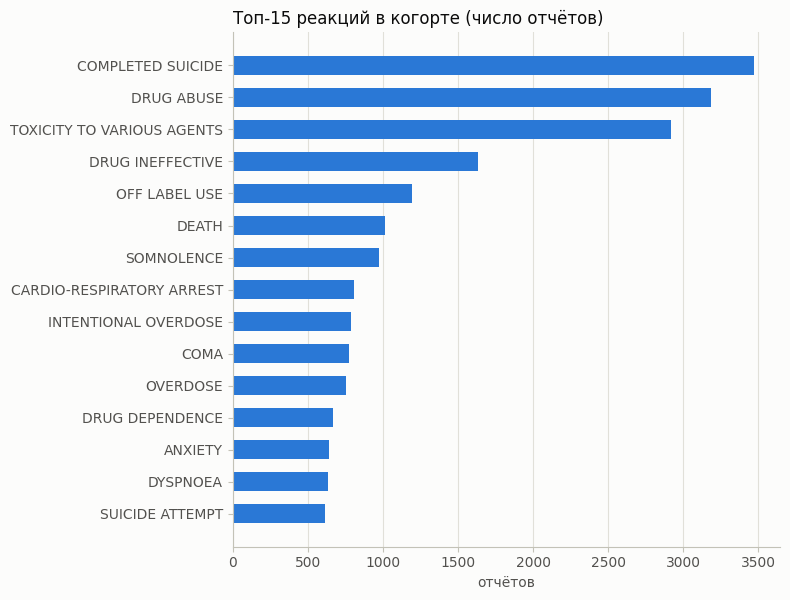

In [9]:
top_rx = rx_cohort["reaction"].value_counts().head(15)
hbar(top_rx, "Топ-15 реакций в когорте (число отчётов)", "отчётов")

**Что видно.** Женщин 52%, мужчин 39,5%, пол не указан у 8%. Средний возраст 47 лет. Серьёзными названы 92% отчётов, и это ожидаемо для отчётов, где препарат указан как подозреваемый: о лёгких случаях сообщают реже. Из-за этой почти полной «серьёзности» показатель плохо различает группы и дальше используется только описательно.

## 5. Исходы по препаратам

Доля отчётов с каждой группой реакций среди отчётов, где соответствующий бензодиазепин указан как подозреваемый. Отчёт с двумя подозреваемыми бензодиазепинами учитывается у обоих. В скобках 95% доверительные интервалы Уилсона.

In [10]:
def share_ci_table(df, group_col, cols):
    out = {}
    for g, sub in df.groupby(group_col):
        row = {}
        for c in cols:
            k, n = int(sub[c].sum()), len(sub)
            lo, hi = wilson(k, n)
            row[c] = f"{k / n:.3f} ({lo:.3f}-{hi:.3f})"
        out[g] = row
    return pd.DataFrame(out).T


merged = cohort.merge(benzo_susp, on="report_id")   # отчёт с двумя подозреваемыми бензодиазепинами учитывается в обоих
by_drug = merged.groupby("benzo")[flags + ["serious"]].mean().round(3)
by_drug.insert(0, "n_reports", merged.groupby("benzo").size())
print(by_drug.to_string())
print()
print("Доля (95% доверительный интервал):")
share_ci_table(merged, "benzo", flags + ["serious"])

            n_reports  dependence  abuse  withdrawal  overdose  overdose_broad  serious
benzo                                                                                  
alprazolam       6908       0.068  0.230       0.025     0.087           0.218    0.937
clonazepam       5164       0.043  0.091       0.031     0.064           0.170    0.914
diazepam         7076       0.077  0.173       0.024     0.102           0.300    0.935
lorazepam        4429       0.029  0.109       0.022     0.072           0.169    0.899

Доля (95% доверительный интервал):


,dependence,abuse,withdrawal,overdose,overdose_broad,serious
alprazolam,0.068 (0.062-0.074),0.230 (0.220-0.240),0.025 (0.021-0.029),0.087 (0.080-0.094),0.218 (0.208-0.228),0.937 (0.931-0.942)
clonazepam,0.043 (0.037-0.048),0.091 (0.084-0.099),0.031 (0.027-0.036),0.064 (0.058-0.072),0.170 (0.160-0.180),0.914 (0.906-0.922)
diazepam,0.077 (0.071-0.084),0.173 (0.164-0.182),0.024 (0.021-0.028),0.102 (0.095-0.109),0.300 (0.289-0.310),0.935 (0.929-0.941)
lorazepam,0.029 (0.024-0.034),0.109 (0.100-0.119),0.022 (0.018-0.027),0.072 (0.064-0.080),0.169 (0.158-0.180),0.899 (0.889-0.907)


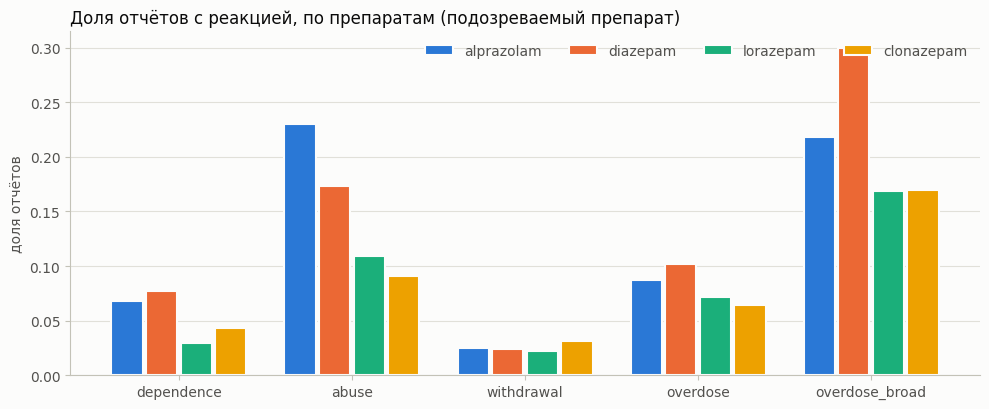

In [11]:
grouped_bars(by_drug.loc[BENZOS, flags].T, "Доля отчётов с реакцией, по препаратам (подозреваемый препарат)")

**Что видно.**

- **Злоупотребление:** алпразолам 23,0%, диазепам 17,3%, лоразепам 10,9%, клоназепам 9,1%. Интервалы алпразолама и диазепама не пересекаются ни друг с другом, ни с остальными.
- **Широкая передозировка:** диазепам 30,0% (28,9-31,0%), остальные 17-22%. Узкая группа даёт тот же порядок (диазепам 10,2%), но различия меньше.
- **Зависимость:** диазепам 7,7% и алпразолам 6,8% против 2,9% у лоразепама.
- **Синдром отмены:** 2,2-3,1% у всех, различия малы.

Различия между препаратами отражают состав отчётов (показания, формы выпуска, распространённость препарата вне назначений врача), а не «опасность» препарата: показания в анализе не учтены.

## 6. Что указывается вместе с бензодиазепинами

Считается доля отчётов когорты, в которых встречается каждый другой препарат (любая роль, названия нормализованы). **Опиоиды** определяются по фармклассу из openFDA (без антагонистов вроде налоксона) и по списку названий на случай, когда класс не определился. Дальше препараты сгруппированы по классам, иначе один класс дробится на множество строк.

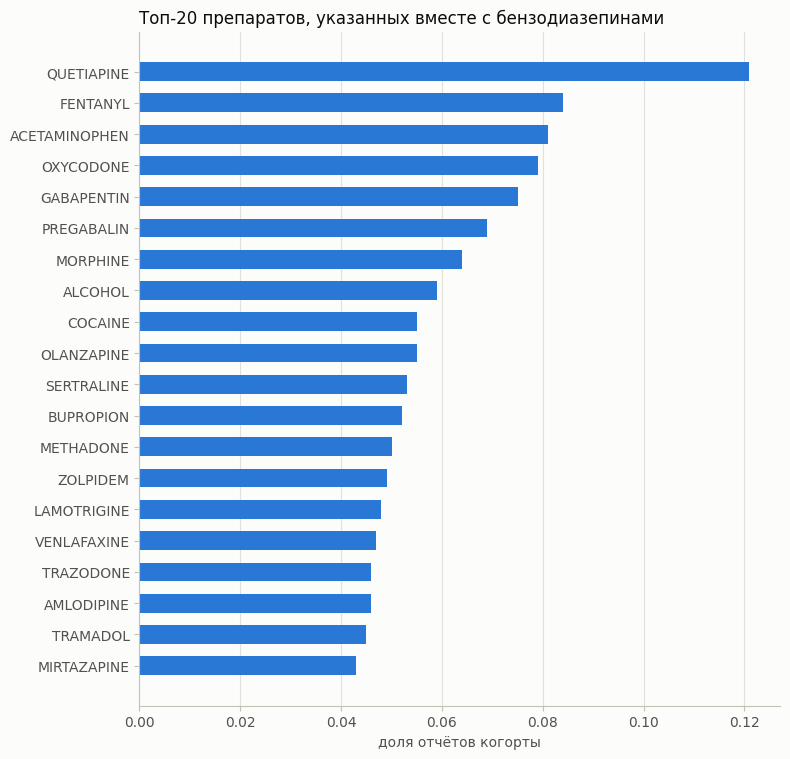

In [12]:
n_cohort = len(cohort)
top_codrugs = (others.drop_duplicates(["report_id", "drug"])
               .groupby("drug").report_id.nunique().sort_values(ascending=False).head(20))
share_codrugs = (top_codrugs / n_cohort).round(3)
hbar(share_codrugs, "Топ-20 препаратов, указанных вместе с бензодиазепинами", "доля отчётов когорты")

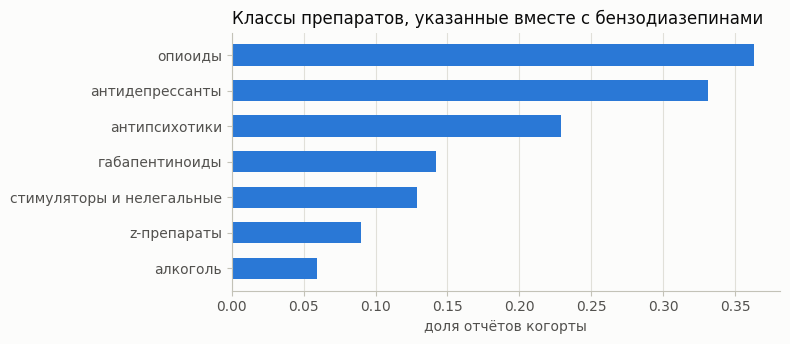

In [13]:
CLASS_RULES = {
    "габапентиноиды":   ["GABAPENTIN", "PREGABALIN"],
    "антипсихотики":    ["QUETIAPINE", "OLANZAPINE", "RISPERIDONE", "ARIPIPRAZOLE", "HALOPERIDOL", "CLOZAPINE",
                         "ZIPRASIDONE", "LURASIDONE", "PALIPERIDONE", "CHLORPROMAZINE"],
    "антидепрессанты":  ["SERTRALINE", "FLUOXETINE", "ESCITALOPRAM", "CITALOPRAM", "PAROXETINE", "VENLAFAXINE",
                         "DULOXETINE", "BUPROPION", "TRAZODONE", "MIRTAZAPINE", "AMITRIPTYLINE", "NORTRIPTYLINE"],
    "z-препараты":      ["ZOLPIDEM", "ZOPICLONE", "ESZOPICLONE", "ZALEPLON"],
    "стимуляторы и нелегальные": ["COCAINE", "METHAMPHETAMINE", "AMPHETAMINE", "CANNABIS", "MARIJUANA",
                                  "HEROIN", "METHYLPHENIDATE"],
}
ALCOHOL_NAMES = {"ALCOHOL", "ETHANOL", "ALCOHOL (ETHANOL)"}


def class_flags(others_df, cohort_df):
    """По одной булевой колонке на класс: есть ли в отчёте хотя бы один препарат класса."""
    out = pd.DataFrame(index=pd.Index(cohort_df.report_id, name="report_id"))
    out["опиоиды"] = cohort_df.set_index("report_id")["with_opioid"]
    for cls_name, names in CLASS_RULES.items():
        mask = others_df.drug.apply(lambda n: any(x in n for x in names))
        out[cls_name] = out.index.isin(set(others_df.loc[mask, "report_id"]))
    out["алкоголь"] = out.index.isin(set(others_df.loc[others_df.drug.isin(ALCOHOL_NAMES), "report_id"]))
    return out


cls_flags = class_flags(others, cohort)
cls_share = cls_flags.mean().sort_values(ascending=False).round(3)
hbar(cls_share, "Классы препаратов, указанные вместе с бензодиазепинами", "доля отчётов когорты")

Исходы в отчётах с каждым классом (строка «вся когорта» для сравнения). Классы пересекаются: в одном отчёте их может быть несколько. На малых классах доли шумные, поэтому рядом указано `n`.

In [14]:
cohort_idx = cohort.set_index("report_id")
rows = [{"класс": "вся когорта", "n": len(cohort), "доля когорты": 1.0,
         **{f: round(cohort[f].mean(), 3) for f in flags + ["serious"]}}]
for cls_name in cls_share.index:
    sub = cohort_idx.loc[cls_flags.index[cls_flags[cls_name]]]
    rows.append({"класс": cls_name, "n": len(sub), "доля когорты": round(len(sub) / len(cohort), 3),
                 **{f: round(sub[f].mean(), 3) for f in flags + ["serious"]}})
pd.DataFrame(rows).set_index("класс")

,n,доля когорты,dependence,abuse,withdrawal,overdose,overdose_broad,serious
класс,,,,,,,,
вся когорта,21396,1.000,0.054,0.155,0.023,0.080,0.214,0.920
опиоиды,7776,0.363,0.072,0.264,0.022,0.082,0.247,0.979
антидепрессанты,7088,0.331,0.032,0.095,0.018,0.104,0.292,0.972
антипсихотики,4895,0.229,0.027,0.086,0.014,0.092,0.254,0.981
габапентиноиды,3030,0.142,0.075,0.172,0.029,0.095,0.285,0.963
стимуляторы и нелегальные,2759,0.129,0.140,0.476,0.030,0.055,0.233,0.986
z-препараты,1928,0.090,0.068,0.085,0.015,0.141,0.299,0.981
алкоголь,1273,0.059,0.051,0.282,0.012,0.065,0.293,0.995


**Что видно.** Опиоиды указаны в 36% отчётов, антидепрессанты в 33%, антипсихотики в 23%, габапентиноиды в 14%, стимуляторы и нелегальные вещества в 13%, z-препараты в 9%, алкоголь в 6%. Профили исходов отличаются:

- **Злоупотребление** выше всего при стимуляторах и нелегальных веществах (47,6%) и алкоголе (28,2%), затем при опиоидах (26,4%). Это маркер полипотребления, а не свойство бензодиазепина.
- **Широкая передозировка** выше всего при z-препаратах (29,9%), алкоголе (29,3%) и антидепрессантах (29,2%), в среднем по когорте 21,4%.
- Доля «серьёзных» при любом классе 96-99,5% против 92% по когорте: чем больше препаратов в отчёте, тем вероятнее он серьёзный.

## 7. Опиоиды: сравнение долей

Отчёты с опиоидом и без него, с 95% доверительными интервалами Уилсона. Это описательное сравнение, а не оценка риска: у пациентов с опиоидами может отличаться состав и причина обращения.

In [15]:
def compare_opioid(df):
    rows = []
    for flag in flags + ["serious"]:
        for g, sub in df.groupby("with_opioid"):
            k, n = int(sub[flag].sum()), len(sub)
            lo, hi = wilson(k, n)
            rows.append({"outcome": flag, "with_opioid": g, "n": n, "share": round(k / n, 3),
                         "ci95": f"{lo:.3f}-{hi:.3f}"})
    return pd.DataFrame(rows).pivot(index="outcome", columns="with_opioid", values=["n", "share", "ci95"])


print("Доля отчётов с опиоидом:", round(cohort.with_opioid.mean(), 3))
compare_opioid(cohort)

Доля отчётов с опиоидом: 0.363


n        share                ci95             
with_opioid     False True   False  True         False        True 
outcome                                                            
abuse           13620  7776  0.093  0.264  0.089-0.098  0.254-0.274
dependence      13620  7776  0.044  0.072  0.040-0.047  0.066-0.078
overdose        13620  7776  0.078  0.082  0.074-0.083  0.076-0.088
overdose_broad  13620  7776  0.195  0.247  0.189-0.202  0.238-0.257
serious         13620  7776  0.887  0.979  0.882-0.892  0.975-0.982
withdrawal      13620  7776  0.023  0.022  0.021-0.026  0.019-0.026

**Что видно.**

- **Широкая передозировка:** 24,7% против 19,5%, интервалы не пересекаются. Узкая `overdose` почти не различается (8,2% против 7,8%): основная разница приходится на токсичность и отравления, а не на термины «overdose».
- **Злоупотребление:** 26,4% против 9,3%, зависимость 7,2% против 4,4%. Разница отражает контекст полипотребления: в таких отчётах много препаратов, в том числе нелегальных.
- **«Серьёзные»:** 97,9% против 88,7%. Показатель почти упёрся в потолок, поэтому содержательных выводов из него делать нельзя.
- **Синдром отмены** не различается (2,2% против 2,3%).

## 8. Проверка устойчивости: отчёты с флагом `duplicate`

Те же расчёты повторены без отчётов, которые FDA пометила как имеющие дубли. Если выводы совпадают, они не зависят от того, как обращаться с дублями.

In [16]:
cohort_nd, susp_nd, others_nd, _ = make_cohort(drop_flagged_dups=True)
print(f"Когорта: {len(cohort)} (все) и {len(cohort_nd)} (без помеченных дублей)")

summary = pd.concat({"все": cohort[flags + ["serious"]].mean(),
                     "без дублей": cohort_nd[flags + ["serious"]].mean()}, axis=1).round(3)
print(summary.to_string())
print()
print("Отчёты с опиоидом vs без, без помеченных дублей:")
compare_opioid(cohort_nd)

Когорта: 21396 (все) и 7680 (без помеченных дублей)
                  все  без дублей
dependence      0.054       0.052
abuse           0.155       0.132
withdrawal      0.023       0.024
overdose        0.080       0.067
overdose_broad  0.214       0.194
serious         0.920       0.886

Отчёты с опиоидом vs без, без помеченных дублей:


n        share                ci95             
with_opioid    False True   False  True         False        True 
outcome                                                           
abuse           4950  2730  0.056   0.27  0.050-0.063  0.253-0.287
dependence      4950  2730  0.044  0.067  0.038-0.050  0.058-0.077
overdose        4950  2730  0.062  0.077  0.056-0.069  0.068-0.088
overdose_broad  4950  2730  0.176  0.227  0.166-0.187  0.211-0.243
serious         4950  2730  0.842  0.968  0.831-0.852  0.960-0.974
withdrawal      4950  2730  0.026   0.02  0.022-0.031  0.015-0.026

**Что видно.** Флаг `duplicate = 1` имеют 58,6% отчётов, без них когорта сокращается с 21 396 до 7680 отчётов. Доли зависимости и отмены почти не меняются (5,4% и 5,2%; 2,3% и 2,4%). Злоупотребление, передозировки и «серьёзные» без дублей ниже (15,5% → 13,2%; 8,0% → 6,7%; 92,0% → 88,6%). Направление различий между отчётами с опиоидами и без них сохраняется для злоупотребления, зависимости, широкой передозировки и «серьёзных». Для узкой передозировки без дублей разница появляется (7,7% против 6,2%), а на всех отчётах её нет. Для отмены без дублей у отчётов с опиоидами доля чуть ниже (2,0% против 2,6%), но интервалы пересекаются.

**Вывод.** Направление результатов устойчиво, абсолютные числа зависят от обращения с дублями. Поэтому дальше все оценки даны в обоих вариантах.

## 9. Опиоиды и передозировка с поправками: логистическая регрессия

Сравнение долей не учитывает, что отчёты с опиоидами отличаются составом: возрастом, числом препаратов, сопутствующими классами. Здесь опиоиды оцениваются в четырёх моделях, где поправки добавляются по шагам:

| модель | поправки |
|---|---|
| M0 | без поправок (то же, что сравнение долей, но в виде отношения шансов) |
| M1 | возраст (группы), пол, год, препарат |
| M2 | M1 + число прочих препаратов в отчёте (без опиоидов) |
| M3 | M2 + классы сопутствующих (антидепрессанты, антипсихотики, габапентиноиды, z-препараты, стимуляторы и нелегальные, алкоголь) |

Результат: **отношение шансов (ОШ) для опиоидов** с 95% доверительным интервалом (1 означает отсутствие связи). Если ОШ падает к 1 по мере добавления поправок, связь объясняется контекстом, а не опиоидами. Пропуски в возрасте и поле выделены в отдельные категории, чтобы не терять отчёты. Модель оценивается собственной реализацией метода Ньютона, дополнительные библиотеки не нужны.

Исходы: широкая передозировка, узкая передозировка и злоупотребление. Исход «серьёзные» исключён: более 90% отчётов его содержат, оценки неустойчивы и не поддаются интерпретации.

In [17]:
import numpy as np


def fit_logit(X, y, max_iter=100, tol=1e-7, ridge=1e-8):
    """Логистическая регрессия методом Ньютона (IRLS). X содержит константу в первом столбце."""
    k = X.shape[1]
    beta = np.zeros(k)
    converged = False
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
        w = p * (1 - p)
        grad = X.T @ (y - p) - ridge * beta
        hess = (X * w[:, None]).T @ X + ridge * np.eye(k)
        step = np.linalg.solve(hess, grad)
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            converged = True
            break
    p = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
    w = p * (1 - p)
    hess = (X * w[:, None]).T @ X + ridge * np.eye(k)
    se = np.sqrt(np.diag(np.linalg.inv(hess)))
    return beta, se, converged


def build_features(cohort_df, susp_df, others_df):
    """Признаки для регрессии: по строке на отчёт когорты (индекс - report_id)."""
    c = cohort_df.set_index("report_id")
    f = pd.DataFrame(index=c.index)
    f["opioid"] = c.with_opioid.astype(float)

    age = pd.to_numeric(c.age, errors="coerce")
    age_cat = pd.cut(age, [-1, 17, 34, 49, 64, 200], labels=["<18", "18-34", "35-49", "50-64", "65+"]).astype(object)
    age_cat = age_cat.where(age.notna(), "неизвестен")
    for lab in ["<18", "18-34", "50-64", "65+", "неизвестен"]:          # референс: 35-49
        f["age_" + lab] = (age_cat == lab).astype(float)

    f["sex_M"] = (c.sex == "M").astype(float)                           # референс: F
    f["sex_неизвестен"] = c.sex.isna().astype(float)

    years = sorted(c.year.dropna().unique())
    for y in years[1:]:                                                 # референс: первый год
        f[f"year_{int(y)}"] = (c.year == y).astype(float)

    by_report = susp_df.groupby("report_id").benzo.agg(set)             # референс: alprazolam
    for b in BENZOS[1:]:
        f["benzo_" + b] = [float(b in by_report.get(i, ())) for i in f.index]

    n_other = others_df[~others_df.is_opioid].groupby("report_id").drug.nunique().reindex(f.index).fillna(0)
    n_cat = pd.cut(n_other, [-1, 0, 2, 4, 9, 1000], labels=["0", "1-2", "3-4", "5-9", "10+"]).astype(object)
    for lab in ["0", "3-4", "5-9", "10+"]:                              # референс: 1-2 прочих препарата
        f["nopi_" + lab] = (n_cat == lab).astype(float)

    cf = class_flags(others_df, cohort_df)
    for name in cf.columns:
        if name != "опиоиды":
            f["cls_" + name] = cf[name].astype(float)
    return f


MODEL_PREFIXES = {
    0: ["opioid"],
    1: ["opioid", "age_", "sex_", "year_", "benzo_"],
    2: ["opioid", "age_", "sex_", "year_", "benzo_", "nopi_"],
    3: ["opioid", "age_", "sex_", "year_", "benzo_", "nopi_", "cls_"],
}
MODEL_LABELS = {0: "M0: только опиоиды", 1: "M1: + возраст, пол, год, препарат",
                2: "M2: + число прочих препаратов", 3: "M3: + классы сопутствующих"}


def model_cols(feats, level):
    pref = MODEL_PREFIXES[level]
    cols = [c for c in feats.columns if c == "opioid" or any(c.startswith(p) for p in pref[1:])]
    return [c for c in cols if feats[c].std() > 0]                      # константные столбцы выбрасываем

In [18]:
OUTCOMES_LR = ["overdose_broad", "overdose", "abuse"]
variants = {"все отчёты": (cohort, benzo_susp, others),
            "без помеченных дублей": (cohort_nd, susp_nd, others_nd)}

fits, rows = {}, []
for vname, (coh, su, oth) in variants.items():
    feats = build_features(coh, su, oth)
    cidx = coh.set_index("report_id")
    for outcome in OUTCOMES_LR:
        y = cidx.loc[feats.index, outcome].astype(float).values
        for level in MODEL_PREFIXES:
            cols = model_cols(feats, level)
            X = np.column_stack([np.ones(len(feats)), feats[cols].values.astype(float)])
            beta, se, ok = fit_logit(X, y)
            j = 1 + cols.index("opioid")
            rows.append({"cohort": vname, "outcome": outcome, "model": level, "n": len(y),
                         "OR": float(np.exp(beta[j])), "lo": float(np.exp(beta[j] - 1.96 * se[j])),
                         "hi": float(np.exp(beta[j] + 1.96 * se[j])), "converged": ok})
            fits[(vname, outcome, level)] = (cols, beta, se)

lr = pd.DataFrame(rows)
bad = lr[~lr.converged]
if bad.empty:
    print("Все модели сошлись.")
else:
    print("Не сошлось моделей:", len(bad), "из", len(lr))
    print(bad[["cohort", "outcome", "model"]].to_string(index=False))
lr["ОШ (95% ДИ)"] = lr.apply(lambda r: f"{r.OR:.2f} ({r.lo:.2f}-{r.hi:.2f})", axis=1)
print("Отношение шансов для опиоидов (1 = нет связи):")
lr.pivot_table(index=["outcome", "cohort"], columns="model", values="ОШ (95% ДИ)", aggfunc="first").rename(columns=MODEL_LABELS)

Все модели сошлись.
Отношение шансов для опиоидов (1 = нет связи):


model                                M0: только опиоиды M1: + возраст, пол, год, препарат M2: + число прочих препаратов  \
outcome        cohort                                                                                                     
abuse          без помеченных дублей   6.23 (5.37-7.22)                  5.35 (4.57-6.26)              5.31 (4.52-6.25)   
               все отчёты              3.48 (3.22-3.76)                  2.92 (2.69-3.17)              2.97 (2.73-3.23)   
overdose       без помеченных дублей   1.27 (1.06-1.52)                  1.32 (1.09-1.59)              1.30 (1.07-1.58)   
               все отчёты              1.05 (0.94-1.16)                  1.02 (0.92-1.14)              1.04 (0.94-1.16)   
overdose_broad без помеченных дублей   1.37 (1.22-1.54)                  1.25 (1.11-1.41)              1.31 (1.16-1.49)   
               все отчёты              1.35 (1.27-1.45)                  1.27 (1.19-1.37)              1.38 (1.28-1.48)   

model                                M3: + классы сопутствующих  
outcome        cohort                                            
abuse          без помеченных дублей           4.13 (3.49-4.90)  
               все отчёты                      2.31 (2.12-2.53)  
overdose       без помеченных дублей           1.41 (1.15-1.73)  
               все отчёты                      1.11 (1.00-1.24)  
overdose_broad без помеченных дублей           1.39 (1.22-1.58)  
               все отчёты                      1.42 (1.32-1.53)

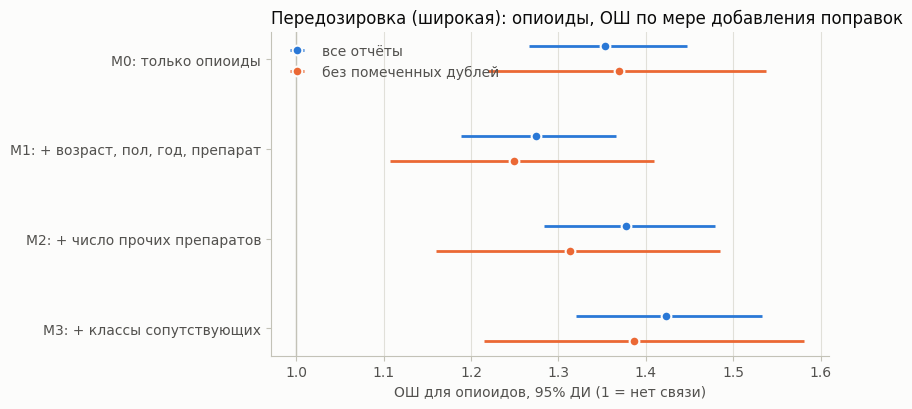

In [19]:
fp = lr[lr.outcome == "overdose_broad"]
VARIANT_COLOR = {"все отчёты": "#2a78d6", "без помеченных дублей": "#eb6834"}

fig, ax = plt.subplots(figsize=(8.5, 4.2), facecolor=SURFACE)
for vi, (vname, color) in enumerate(VARIANT_COLOR.items()):
    sub = fp[fp.cohort == vname].sort_values("model")
    ys = [m + (vi - 0.5) * 0.28 for m in sub.model]
    ax.errorbar(sub.OR, ys, xerr=[sub.OR - sub.lo, sub.hi - sub.OR], fmt="o", color=color, ms=7,
                mec=SURFACE, mew=1.5, elinewidth=2, capsize=0, label=vname)
ax.axvline(1, color=AXIS, linewidth=1)
ax.set_yticks(list(MODEL_LABELS))
ax.set_yticklabels(list(MODEL_LABELS.values()))
ax.invert_yaxis()
ax.set_xlabel("ОШ для опиоидов, 95% ДИ (1 = нет связи)", color=INK2)
ax.set_title("Передозировка (широкая): опиоиды, ОШ по мере добавления поправок", loc="left", color=INK, fontsize=12)
style_ax(ax, "x")
ax.legend(frameon=False, loc="best", labelcolor=INK2)
plt.tight_layout()
plt.show()

**Что видно.**

- **Широкая передозировка:** ОШ 1,35 без поправок и 1,42 (1,32-1,53) в полной модели. Без отчётов с флагом дубля 1,37 и 1,39 (1,22-1,58). Поправки связь не убирают, она остаётся около 1,4 в обеих версиях данных.
- **Узкая передозировка:** на всех отчётах ОШ 1,02-1,11 (в полной модели 1,11, интервал 1,00-1,24, на границе значимости), без дублей 1,27-1,41. Эта связь зависит от обращения с дублями и устойчивой не считается.
- **Злоупотребление:** ОШ положителен во всех моделях и после поправок остаётся выше 2 (2,31 на всех отчётах, 4,13 без дублей). Направление устойчиво, величина зависит от версии данных.

Коэффициенты итоговой модели M3 для широкой передозировки (все отчёты): какие факторы связаны с исходом помимо опиоидов.

In [20]:
cols, beta, se = fits[("все отчёты", "overdose_broad", 3)]
coef = pd.DataFrame({"ОШ": np.exp(beta[1:]), "lo": np.exp(beta[1:] - 1.96 * se[1:]),
                     "hi": np.exp(beta[1:] + 1.96 * se[1:])}, index=cols)
coef["ОШ (95% ДИ)"] = coef.apply(lambda r: f"{r['ОШ']:.2f} ({r.lo:.2f}-{r.hi:.2f})", axis=1)
print("Референсы: возраст 35-49, пол F, препарат alprazolam, 1-2 прочих препарата, первый год выборки.")
coef.sort_values("ОШ", ascending=False)[["ОШ", "ОШ (95% ДИ)"]].round({"ОШ": 2})

Референсы: возраст 35-49, пол F, препарат alprazolam, 1-2 прочих препарата, первый год выборки.


,ОШ,ОШ (95% ДИ)
sex_неизвестен,2.03,2.03 (1.75-2.37)
cls_антидепрессанты,1.97,1.97 (1.82-2.13)
benzo_diazepam,1.69,1.69 (1.56-1.83)
cls_z-препараты,1.65,1.65 (1.47-1.85)
opioid,1.42,1.42 (1.32-1.53)
cls_габапентиноиды,1.42,1.42 (1.29-1.57)
year_2024,1.29,1.29 (1.13-1.47)
year_2025,1.25,1.25 (1.10-1.43)
cls_алкоголь,1.23,1.23 (1.08-1.41)
year_2021,1.22,1.22 (1.07-1.39)


**Что видно.**

- **Класс сопутствующих сильнее опиоидов:** антидепрессанты ОШ 1,97, z-препараты 1,65, опиоиды и габапентиноиды по 1,42, алкоголь 1,23, антипсихотики 1,13. При стимуляторах и нелегальных веществах ОШ ниже 1 (0,70): там преобладает злоупотребление, а не передозировка.
- **Препарат:** диазепам против алпразолама ОШ 1,69 (1,56-1,83), лоразепам 0,80 и клоназепам 0,78. Тот же порядок получился по долям и по PRR в следующем разделе.
- **Возраст:** старше 65 лет шансы вдвое ниже (0,42 против 35-49), 50-64 года 0,67. Моложе 35 лет отличий нет. **Пол** не влияет (0,98).
- **Число прочих препаратов:** и полное отсутствие (0,52), и очень много (10 и более, 0,35) связаны с меньшими шансами по сравнению с 1-2 препаратами.
- **Неизвестный пол** даёт ОШ 2,03, неизвестный возраст 0,55. Такие связи отражают разные источники отчётов, а не медицинский эффект.
- **Год:** относительно первого года выборки в 2021-2025 годах ОШ 1,11-1,29, значимо выше 1 в 2021, 2023, 2024 и 2025 годах. Причина не установлена: это может быть и изменение практики кодирования терминов.

## 10. Сигналы безопасности: PRR и ROR по всей базе FAERS

Подвыборка из разделов 3-9 не годится для оценки «непропорциональности», поэтому здесь числа берутся прямо из API по всей базе за те же годы (`count`-запросы, около 90 штук, результат кэшируется в `data/`).

Для препарата D и реакции R строится таблица 2×2:

| | реакция R | нет R |
|---|---|---|
| препарат D | a | b |
| все остальные отчёты | c | d |

- **PRR** = (a / (a+b)) / (c / (c+d)): во сколько раз реакция чаще встречается в отчётах с препаратом, чем в остальных.
- **ROR** = (a·d) / (b·c) с 95% доверительным интервалом.
- **Сигнал** по критериям Эванса: a ≥ 3, PRR ≥ 2, χ² ≥ 4.

**Ограничения метода.** API не позволяет требовать, чтобы препарат был именно подозреваемым, поэтому учитывается присутствие препарата в любой роли. Это размывает оценки в сторону единицы. Фон составляют все остальные препараты, а не другие бензодиазепины. Сигнал означает «повод изучить», а не доказательство причинности.

In [21]:
WINDOW = f"receivedate:[{YEARS[0]}0101 TO {YEARS[-1]}1231]"
PRR_TERMS = ["DRUG DEPENDENCE", "DRUG ABUSE", "WITHDRAWAL SYNDROME", "DRUG WITHDRAWAL SYNDROME",
             "OVERDOSE", "INTENTIONAL OVERDOSE", "TOXICITY TO VARIOUS AGENTS",
             "SOMNOLENCE", "RESPIRATORY DEPRESSION", "COMA", "FALL", "AMNESIA"]


def count(search):
    return fda_get({"search": search, "limit": 1})["meta"]["results"]["total"]


prr_cache = DATA_DIR / "prr_counts.json"
if prr_cache.exists():
    counts = json.loads(prr_cache.read_text())
else:
    counts = {"window": WINDOW, "N_total": count(WINDOW), "drug": {}, "reaction": {}, "both": {}}
    for d in BENZOS:
        counts["drug"][d] = count(f'patient.drug.openfda.generic_name:"{d}" AND {WINDOW}')
    for t in PRR_TERMS:
        counts["reaction"][t] = count(f'patient.reaction.reactionmeddrapt.exact:"{t}" AND {WINDOW}')
        for d in BENZOS:
            counts["both"][f"{d}|{t}"] = count(
                f'patient.drug.openfda.generic_name:"{d}" AND patient.reaction.reactionmeddrapt.exact:"{t}" AND {WINDOW}')
            time.sleep(0.2)
        print(f"  готово: {t}")
    prr_cache.write_text(json.dumps(counts))

print("Всего отчётов в окне:", counts["N_total"])
print("Отчётов по препаратам:", counts["drug"])

Всего отчётов в окне: 9974571
Отчётов по препаратам: {'alprazolam': 76038, 'diazepam': 49441, 'lorazepam': 75464, 'clonazepam': 62409}


In [22]:
def disproportionality(a, n_drug, n_reac, n_total):
    """PRR, ROR и критерии сигнала по таблице 2x2."""
    b, c = n_drug - a, n_reac - a
    d = n_total - n_drug - n_reac + a
    res = {"a": a, "PRR": float("nan"), "chi2": float("nan"), "ROR": float("nan"),
           "ROR_lo": float("nan"), "ROR_hi": float("nan"), "signal": False}
    if min(a, b, c, d) <= 0:
        return res
    prr = (a / n_drug) / (c / (c + d))
    res["PRR"] = prr
    res["chi2"] = n_total * (a * d - b * c) ** 2 / ((a + b) * (c + d) * (a + c) * (b + d))
    ror = (a * d) / (b * c)
    se = math.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    res["ROR"] = ror
    res["ROR_lo"], res["ROR_hi"] = ror * math.exp(-1.96 * se), ror * math.exp(1.96 * se)
    res["signal"] = bool(a >= 3 and prr >= 2 and res["chi2"] >= 4)
    return res


rows = []
for t in PRR_TERMS:
    for d in BENZOS:
        r = disproportionality(counts["both"][f"{d}|{t}"], counts["drug"][d], counts["reaction"][t], counts["N_total"])
        rows.append({"drug": d, "reaction": t, "N_drug": counts["drug"][d], "N_reaction": counts["reaction"][t], **r})
prr_df = pd.DataFrame(rows)

show = prr_df.copy()
show["ROR (95% ДИ)"] = show.apply(
    lambda r: "-" if pd.isna(r.ROR) else f"{r.ROR:.2f} ({r.ROR_lo:.2f}-{r.ROR_hi:.2f})", axis=1)
show[["PRR", "chi2"]] = show[["PRR", "chi2"]].round(2)
print("Реакции, отмеченные как сигнал (критерии Эванса):")
show[show.signal][["drug", "reaction", "a", "PRR", "chi2", "ROR (95% ДИ)"]].sort_values(["reaction", "PRR"], ascending=[True, False])

Реакции, отмеченные как сигнал (критерии Эванса):


,drug,reaction,a,PRR,chi2,ROR (95% ДИ)
46,lorazepam,AMNESIA,1015,6.09,4139.69,6.16 (5.79-6.57)
45,diazepam,AMNESIA,420,3.76,835.96,3.78 (3.43-4.17)
47,clonazepam,AMNESIA,529,3.76,1050.27,3.79 (3.47-4.13)
44,alprazolam,AMNESIA,442,2.57,415.32,2.58 (2.34-2.83)
37,diazepam,COMA,1927,21.74,34475.78,22.58 (21.53-23.69)
36,alprazolam,COMA,1597,11.47,14058.27,11.70 (11.11-12.32)
38,lorazepam,COMA,846,5.88,3286.18,5.94 (5.54-6.36)
39,clonazepam,COMA,635,5.29,2139.33,5.33 (4.92-5.77)
5,diazepam,DRUG ABUSE,3989,19.71,64788.90,21.35 (20.64-22.08)
4,alprazolam,DRUG ABUSE,5387,17.87,75784.41,19.16 (18.60-19.73)


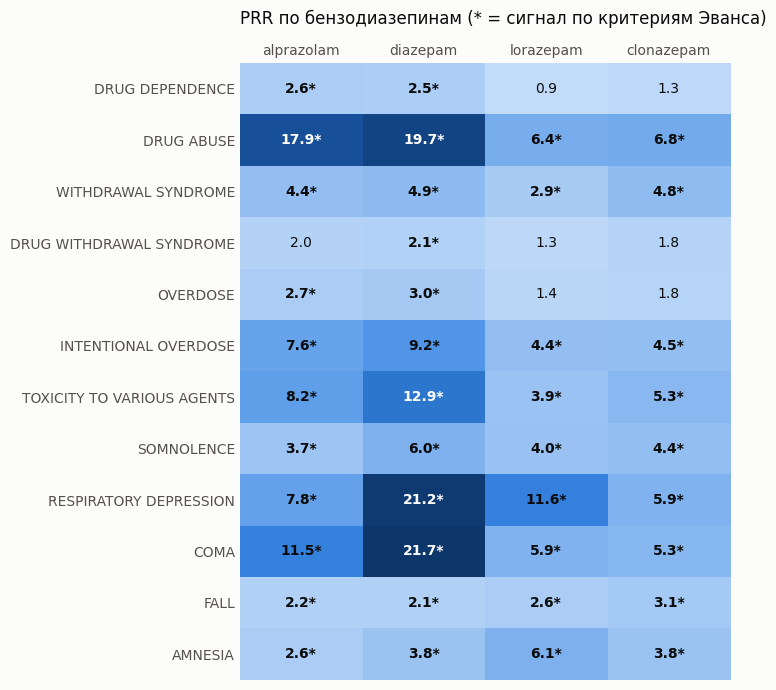

In [23]:
pivot = prr_df.pivot(index="reaction", columns="drug", values="PRR").loc[PRR_TERMS, BENZOS]
sig = prr_df.pivot(index="reaction", columns="drug", values="signal").loc[PRR_TERMS, BENZOS]

fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(PRR_TERMS) + 1.6), facecolor=SURFACE)
vmax = max(2.5, float(pivot.max().max()))
im = ax.imshow(pivot.values, cmap=SEQ_BLUE, vmin=0, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(BENZOS)))
ax.set_xticklabels(BENZOS, color=INK2)
ax.set_yticks(range(len(PRR_TERMS)))
ax.set_yticklabels(PRR_TERMS, color=INK2)
ax.xaxis.tick_top()
for i in range(len(PRR_TERMS)):
    for j in range(len(BENZOS)):
        v = pivot.values[i, j]
        label = "-" if pd.isna(v) else f"{v:.1f}" + ("*" if sig.values[i, j] else "")
        dark_cell = (not pd.isna(v)) and v / vmax > 0.55
        ax.text(j, i, label, ha="center", va="center", color="white" if dark_cell else INK,
                fontweight="bold" if sig.values[i, j] else "normal", fontsize=10)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("PRR по бензодиазепинам (* = сигнал по критериям Эванса)", loc="left", color=INK, fontsize=12, pad=28)
plt.tight_layout()
plt.show()

**Что видно.** В окне 9 974 571 отчёт, критерии Эванса отметили 41 пару из 48. При таком объёме χ² всегда огромен, поэтому флаг почти ничего не отсекает и нужно смотреть на величину PRR и интервал ROR. Самые сильные связи:

- кома у диазепама (PRR 21,7) и алпразолама (11,5);
- угнетение дыхания у диазепама (21,2) и лоразепама (11,6);
- злоупотребление у диазепама (19,7) и алпразолама (17,9) против 6-7 у лоразепама и клоназепама;
- токсичность (`TOXICITY TO VARIOUS AGENTS`) у диазепама (12,9);
- амнезия у лоразепама (6,1) против 2,6-3,8 у остальных.

Диазепам стабильно лидирует по исходам, связанным с передозировкой, алпразолам по злоупотреблению, лоразепам по амнезии. Диазепам применяют и при судорогах, и при алкогольной абстиненции, поэтому часть его сигналов может отражать показания.

### Сигналы по группам терминов

Одно клиническое понятие в FAERS распадается на несколько терминов (`WITHDRAWAL SYNDROME` и `DRUG WITHDRAWAL SYNDROME`, разные виды передозировки). Поэтому здесь PRR и ROR считаются для **объединённых групп** (поиск через `OR`, отчёт с несколькими терминами группы считается один раз). Группы соответствуют тем, что использовались в когорте. Показан ROR с доверительным интервалом.

Если API неверно обработает `OR`, ячейка остановится с понятной ошибкой и ничего не закэширует: объединение не может дать число меньше, чем любой из его терминов.

In [24]:
GROUPS = {
    "зависимость":    ["DRUG DEPENDENCE", "DEPENDENCE", "SUBSTANCE DEPENDENCE", "DRUG USE DISORDER", "SUBSTANCE USE DISORDER", "DRUG TOLERANCE"],
    "злоупотребление": ["DRUG ABUSE", "SUBSTANCE ABUSE", "DRUG ABUSER"],
    "синдром отмены": ["WITHDRAWAL SYNDROME", "DRUG WITHDRAWAL SYNDROME", "DRUG WITHDRAWAL CONVULSIONS"],
    "передозировка":  ["OVERDOSE", "INTENTIONAL OVERDOSE", "ACCIDENTAL OVERDOSE", "PRESCRIBED OVERDOSE"],
    "передозировка (широкая)": ["OVERDOSE", "INTENTIONAL OVERDOSE", "ACCIDENTAL OVERDOSE", "PRESCRIBED OVERDOSE",
                                "TOXICITY TO VARIOUS AGENTS", "POISONING DELIBERATE", "POISONING", "ACCIDENTAL POISONING"],
}


def or_query(terms):
    return "(" + " OR ".join(f'patient.reaction.reactionmeddrapt.exact:"{t}"' for t in terms) + ")"


grp_cache = DATA_DIR / "prr_groups.json"
if grp_cache.exists():
    gcounts = json.loads(grp_cache.read_text())
else:
    gcounts = {"reaction": {}, "both": {}}
    for g, terms in GROUPS.items():
        gcounts["reaction"][g] = count(f"{or_query(terms)} AND {WINDOW}")
        for d in BENZOS:
            gcounts["both"][f"{d}|{g}"] = count(
                f'patient.drug.openfda.generic_name:"{d}" AND {or_query(terms)} AND {WINDOW}')
            time.sleep(0.2)
        # проверка: объединение не меньше любого из уже известных одиночных терминов
        known = [counts["reaction"][t] for t in terms if t in counts["reaction"]]
        if known and gcounts["reaction"][g] < max(known):
            raise RuntimeError(
                f"Группа «{g}»: объединённый запрос вернул {gcounts['reaction'][g]}, а один из её терминов даёт {max(known)}. "
                "Похоже, API не принял OR. Кэш не сохранён.")
        print(f"  готово: {g}")
    grp_cache.write_text(json.dumps(gcounts))

rows = []
for g in GROUPS:
    for d in BENZOS:
        r = disproportionality(gcounts["both"][f"{d}|{g}"], counts["drug"][d], gcounts["reaction"][g], counts["N_total"])
        rows.append({"group": g, "drug": d, "N_reaction": gcounts["reaction"][g], **r})
grp_df = pd.DataFrame(rows)

show = grp_df.copy()
show["ROR (95% ДИ)"] = show.apply(lambda r: "-" if pd.isna(r.ROR) else f"{r.ROR:.2f} ({r.ROR_lo:.2f}-{r.ROR_hi:.2f})", axis=1)
show["PRR"] = show["PRR"].round(2)
show.pivot(index="group", columns="drug", values="ROR (95% ДИ)").loc[list(GROUPS), BENZOS]

drug,alprazolam,diazepam,lorazepam,clonazepam
group,,,,
зависимость,2.58 (2.50-2.67),3.10 (2.98-3.22),0.78 (0.73-0.82),1.27 (1.21-1.34)
злоупотребление,18.96 (18.43-19.51),22.14 (21.44-22.86),6.89 (6.61-7.18),7.52 (7.19-7.86)
синдром отмены,2.79 (2.64-2.94),3.06 (2.88-3.26),1.80 (1.69-1.92),2.88 (2.72-3.05)
передозировка,3.65 (3.54-3.76),4.38 (4.23-4.53),2.46 (2.37-2.54),2.41 (2.32-2.51)
передозировка (широкая),5.61 (5.48-5.73),8.40 (8.20-8.60),2.95 (2.87-3.04),3.21 (3.12-3.31)


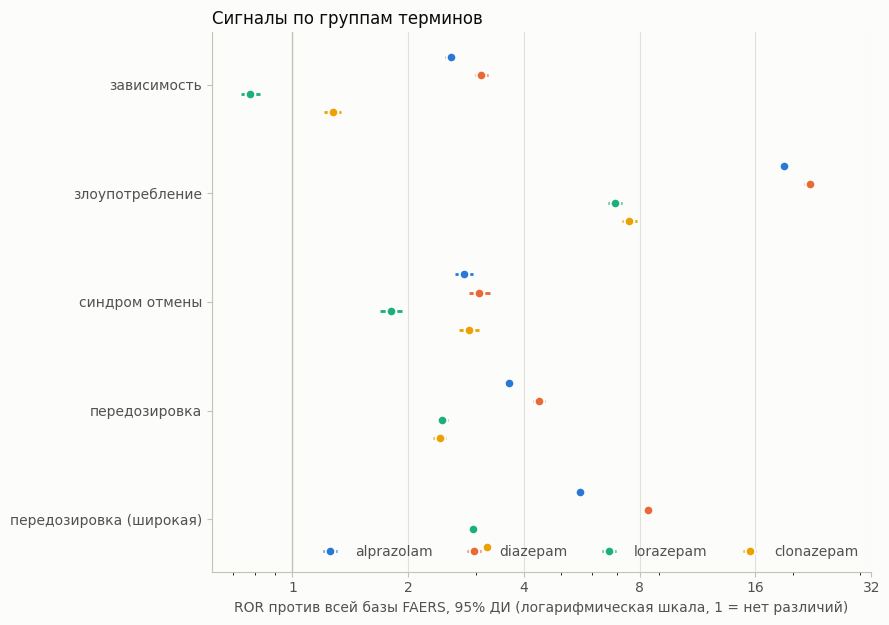

In [25]:
fig, ax = plt.subplots(figsize=(9, 0.95 * len(GROUPS) + 1.6), facecolor=SURFACE)
n = len(BENZOS)
for gi, g in enumerate(GROUPS):
    for di, d in enumerate(BENZOS):
        r = grp_df[(grp_df.group == g) & (grp_df.drug == d)].iloc[0]
        if pd.isna(r.ROR):
            continue
        y = gi + (di - (n - 1) / 2) * 0.17
        ax.errorbar(r.ROR, y, xerr=[[r.ROR - r.ROR_lo], [r.ROR_hi - r.ROR]], fmt="o", color=DRUG_COLOR[d],
                    ms=7, mec=SURFACE, mew=1.5, elinewidth=2, capsize=0, label=d if gi == 0 else None)
ax.axvline(1, color=AXIS, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 8, 16, 32])
ax.set_xticklabels(["1", "2", "4", "8", "16", "32"])
ax.set_yticks(range(len(GROUPS)))
ax.set_yticklabels(list(GROUPS))
ax.invert_yaxis()
ax.set_xlabel("ROR против всей базы FAERS, 95% ДИ (логарифмическая шкала, 1 = нет различий)", color=INK2)
ax.set_title("Сигналы по группам терминов", loc="left", color=INK, fontsize=12)
style_ax(ax, "x")
ax.legend(frameon=False, ncol=n, loc="lower right", labelcolor=INK2)
plt.tight_layout()
plt.show()

**Что видно.**

- **Злоупотребление:** ROR 22,1 у диазепама и 19,0 у алпразолама против 7,5 у клоназепама и 6,9 у лоразепама.
- **Широкая передозировка:** диазепам 8,4, алпразолам 5,6, клоназепам 3,2, лоразепам 3,0. Порядок совпадает с долями в когорте и с регрессией.
- **Синдром отмены:** 1,8-3,1, различия между препаратами небольшие.
- **Зависимость:** 0,8-3,1. У лоразепама ROR ниже 1, то есть реже фона. Фон здесь образуют многие другие препараты с этим термином (например, опиоиды), поэтому слабый сигнал не означает отсутствия зависимости.

## 11. Ограничения

- **Добровольные отчёты.** Доли в FAERS не равны частотам побочек в популяции: на отчётность влияют внимание СМИ, судебные иски, тип отправителя и популярность препарата.
- **Присутствие препарата не доказывает причинность.** Все результаты описывают ассоциации.
- **Подвыборка.** Анализ когорты построен на 13-34% доступных отчётов; репрезентативность выборки не проверялась.
- **Показания и причина обращения не учтены.** Диазепам применяют при судорогах и алкогольной абстиненции, алпразолам и клоназепам при тревоге и панике; это влияет на ожидаемые реакции. Отчёты о намеренной передозировке и о злоупотреблении приходят из разных клинических ситуаций.
- **Дубли.** Часть отчётов в FAERS описывает один и тот же случай. Влияние флага `duplicate` проверено (раздел 8), но полная дедупликация по номеру случая не выполнена.
- **Кодирование терминов.** Одно явление записывается разными терминами MedDRA; группы заданы вручную и могут не покрывать все варианты. `TOXICITY TO VARIOUS AGENTS` включает не только передозировки.
- **Пропуски** в возрасте и поле связаны с исходами и отражают различия источников отчётов.
- **PRR и ROR** считаются по присутствию препарата в отчёте в любой роли, фоном служит вся база; это даёт сравнение «бензодиазепин против всех остальных препаратов», а не между бензодиазепинами.

Работа учебная и не содержит медицинских рекомендаций.